In [3]:

from google.colab import files

uploaded = files.upload()


Saving StandardScaled_Dataset.zip to StandardScaled_Dataset.zip


In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

df = pd.read_csv("StandardScaled_Dataset.zip")

sns.set_theme(style="whitegrid")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df.head())


Dataset shape: (100000, 26)
Missing values: 0
Duplicate rows: 0


,Country,Year,Temperature_Anomaly,CO2_Emissions,Population,Forest_Area,GDP,Renewable_Energy_Usage,Methane_Emissions,Sea_Level_Rise,...,Waste_Management,Per_Capita_Emissions,Industrial_Activity,Air_Pollution_Index,Biodiversity_Index,Ocean_Acidification,Fossil_Fuel_Usage,Energy_Consumption_Per_Capita,Policy_Score,Average_Temperature
0,Country_103,1913,-1.010057,1.339991,-1.356992,0.168706,0.396782,0.922091,1.147639,-0.908733,...,1.131216,-1.334617,-1.592458,0.007597,1.403033,0.087711,-0.378698,-0.761490,1.011754,0.405460
1,Country_180,1950,-0.376563,-0.176455,-0.744016,1.181644,-0.830521,0.635697,0.416550,1.223143,...,0.322356,1.292495,1.217348,-1.412504,1.340615,0.074585,-0.760084,-0.759660,-0.609046,0.958128
2,Country_93,2014,0.383091,-0.148206,-0.594924,0.773548,0.068244,-0.464263,-1.366823,-0.101471,...,1.556665,0.359502,1.165616,0.776956,1.293243,-1.235330,0.403715,-1.312921,-0.431431,-0.001323
3,Country_15,2020,-1.017054,0.014718,1.159639,-1.137005,1.129410,0.951143,-1.044781,1.447789,...,0.417244,-1.235863,-0.106848,-1.313620,-0.177755,-1.508485,1.133378,0.048688,1.281894,-1.141700
4,Country_107,1964,-0.490818,0.655227,-1.055519,-0.193494,1.236454,-1.390229,-0.585422,-0.937630,...,1.191438,1.707501,1.358428,1.554695,-1.465700,0.052522,-0.700248,1.731299,-1.028791,-0.851966


In [7]:

# Select numerical features for correlation analysis
numeric_features = df.select_dtypes(include=np.number).columns.tolist()

# Exclude Year from the PCA feature candidates
pca_features = [col for col in numeric_features if col != "Year"]

print("Number of numerical features:", len(numeric_features))
print("Number of candidate features:", len(pca_features))
print("\nFeatures selected:")
print(pca_features)


Number of numerical features: 25
Number of candidate features: 24

Features selected:
['Temperature_Anomaly', 'CO2_Emissions', 'Population', 'Forest_Area', 'GDP', 'Renewable_Energy_Usage', 'Methane_Emissions', 'Sea_Level_Rise', 'Arctic_Ice_Extent', 'Urbanization', 'Deforestation_Rate', 'Extreme_Weather_Events', 'Average_Rainfall', 'Solar_Energy_Potential', 'Waste_Management', 'Per_Capita_Emissions', 'Industrial_Activity', 'Air_Pollution_Index', 'Biodiversity_Index', 'Ocean_Acidification', 'Fossil_Fuel_Usage', 'Energy_Consumption_Per_Capita', 'Policy_Score', 'Average_Temperature']


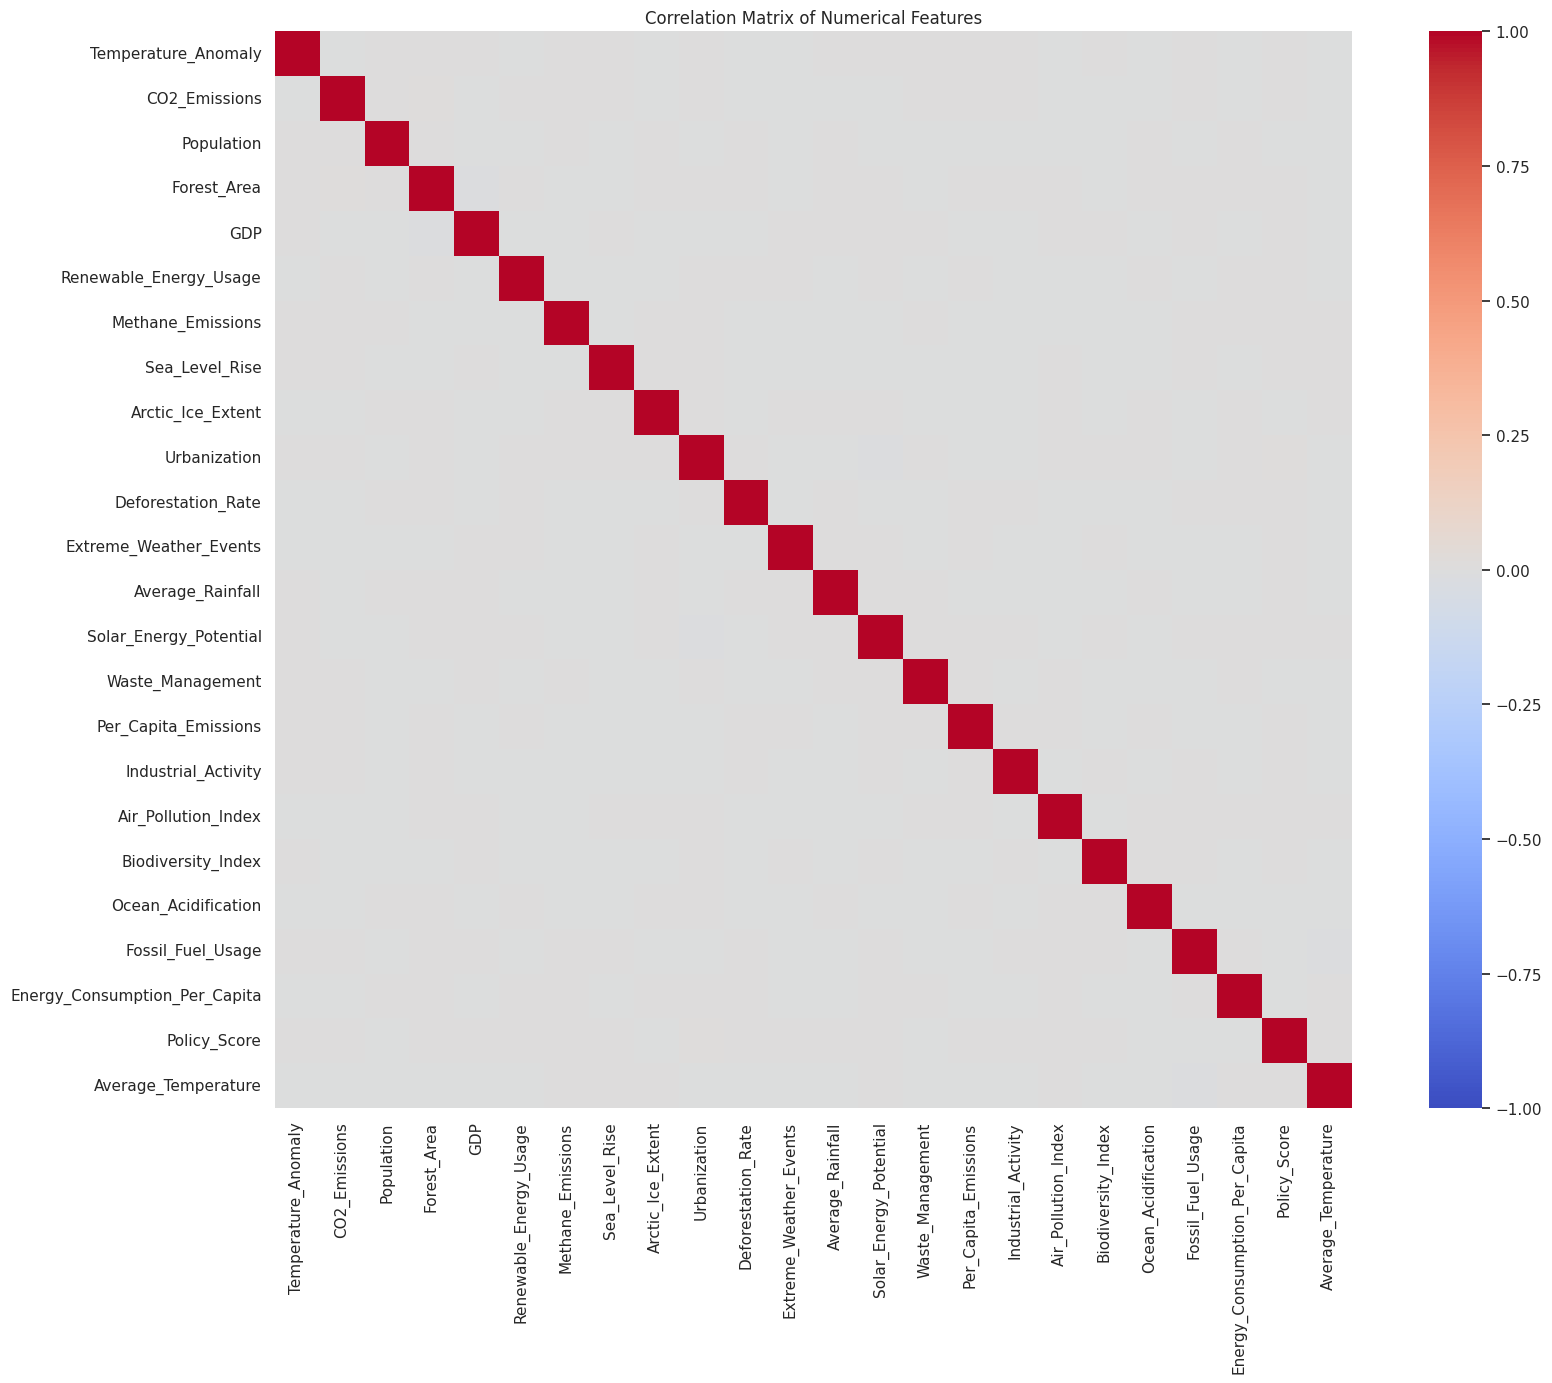

In [8]:

# Calculate feature-to-feature correlations
correlation_matrix = df[pca_features].corr()

# Visualize the correlation matrix
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
        cmap="coolwarm",
            center=0,
                vmin=-1,
                    vmax=1,
                        square=True
                        )

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()


In [10]:

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )

high_corr_pairs = (
        upper_triangle.stack()
            .reset_index()
            )

high_corr_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr_pairs["Absolute Correlation"] = (
                high_corr_pairs["Correlation"].abs()
                )

high_corr_pairs = high_corr_pairs[
                    high_corr_pairs["Absolute Correlation"] >= 0.90
                    ].sort_values(
                        "Absolute Correlation",
                            ascending=False
                            )

print("Highly correlated feature pairs (|r| >= 0.90):")
display(high_corr_pairs)


Highly correlated feature pairs (|r| >= 0.90):


,Feature 1,Feature 2,Correlation,Absolute Correlation


In [11]:

from sklearn.decomposition import PCA

# Prepare the numerical feature matrix
X = df[pca_features].copy()

# Fit PCA to all candidate features
pca = PCA()
X_pca = pca.fit_transform(X)

print("Original number of features:", X.shape[1])
print("Number of principal components:", X_pca.shape[1])
print("\nPCA completed successfully.")


Original number of features: 24
Number of principal components: 24

PCA completed successfully.


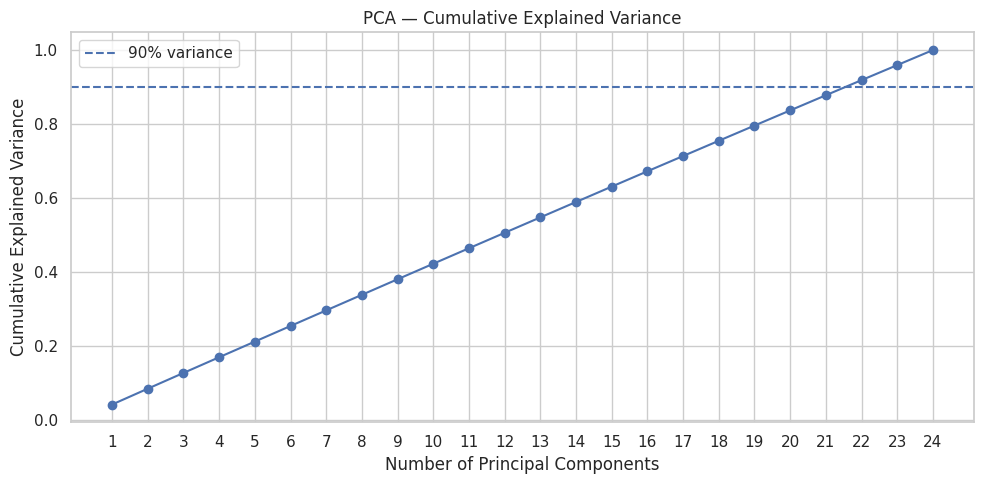

Components needed for at least 90% variance: 22
Cumulative variance retained: 91.88 %


In [12]:

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
        cumulative_variance,
            marker="o"
            )

plt.axhline(y=0.90, linestyle="--", label="90% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA — Cumulative Explained Variance")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("Components needed for at least 90% variance:",
                  components_90)
print("Cumulative variance retained:",round(cumulative_variance[components_90 - 1] * 100, 2), "%")


In [13]:

# Retain enough components to explain at least 90% variance
pca_reduced = PCA(n_components=components_90)

X_reduced = pca_reduced.fit_transform(X)

# Store the reduced features in a DataFrame
pc_columns = [
    f"PC{i+1}" for i in range(components_90)
    ]

df_pca = pd.DataFrame(
        X_reduced,
            columns=pc_columns
            )

print("Original feature count:", X.shape[1])
print("Reduced feature count:", df_pca.shape[1])
print(
                "Explained variance retained:",
                    round(pca_reduced.explained_variance_ratio_.sum() * 100, 2),
                        "%"
                        )

display(df_pca.head())


Original feature count: 24
Reduced feature count: 22
Explained variance retained: 91.88 %


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22
0,-0.568254,-0.045545,-0.124264,0.018125,0.070693,0.319162,-0.337574,0.849254,-0.575289,1.583691,...,0.049632,-0.379145,-2.893022,0.528621,1.057743,0.480562,-0.557827,0.590301,-1.147893,-1.612218
1,0.555060,0.667798,0.068738,0.817797,-0.431243,0.938631,-0.803492,-0.247151,-0.732541,-0.305445,...,1.405393,-0.507629,0.238014,-1.213158,1.777763,1.506914,0.601537,1.371548,0.697566,0.821434
2,-0.929450,1.219817,1.354647,0.442361,1.320665,1.378612,-0.445492,0.241870,0.282801,0.460617,...,-0.219170,-0.364494,0.797803,-0.718851,-0.277213,0.323180,-0.504590,0.437937,-1.393627,1.087383
3,0.004044,0.190983,0.938289,-1.100900,0.586551,-2.544654,0.141410,-0.192140,0.554319,-1.920576,...,-0.415342,-0.944131,-1.052194,-0.219361,0.610915,-1.372605,-0.013684,-0.742848,-1.112896,1.106037
4,-1.012277,0.740651,-0.685360,1.098797,1.869548,1.306553,0.724392,-0.328388,3.334770,0.472436,...,0.899869,-0.219309,0.675265,0.339761,1.240832,-1.002087,1.095687,0.581072,-0.327975,-0.144497


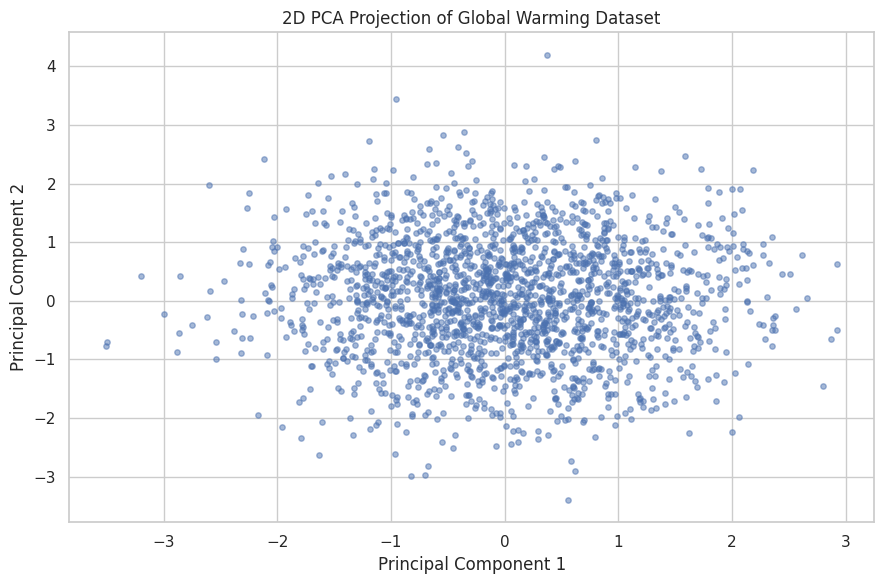

Variance explained by PC1 and PC2: 8.57 %


In [14]:

# Random sample for visualization only
plot_df = df_pca[["PC1", "PC2"]].sample(
    n=2000,
        random_state=42
        )

plt.figure(figsize=(9, 6))

plt.scatter(
            plot_df["PC1"],
                plot_df["PC2"],
                    alpha=0.5,
                        s=15
                        )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Projection of Global Warming Dataset")
plt.tight_layout()
plt.show()

print(
                            "Variance explained by PC1 and PC2:",
                                round(
                                        pca_reduced.explained_variance_ratio_[:2].sum() * 100,
                                                2
                                                    ),
                                                        "%"
                                                        )


In [15]:

# Save the PCA-reduced dataset
df_pca.to_csv("Week7_PCA_Reduced_Dataset.csv", index=False)

# Save explained variance for every retained component
variance_summary = pd.DataFrame({
    "Principal Component": pc_columns,
        "Explained Variance Ratio": pca_reduced.explained_variance_ratio_,
            "Cumulative Explained Variance": np.cumsum(
                    pca_reduced.explained_variance_ratio_
                        )
                        })

variance_summary.to_csv(
                            "Week7_PCA_Explained_Variance.csv",
                                index=False
                                )

                                # Save the high-correlation pairs report
high_corr_pairs.to_csv(
                                    "Week7_High_Correlation_Pairs.csv",
                                        index=False
                                        )

print("Saved files:")
print("1. Week7_PCA_Reduced_Dataset.csv")
print("2. Week7_PCA_Explained_Variance.csv")
print("3. Week7_High_Correlation_Pairs.csv")


Saved files:
1. Week7_PCA_Reduced_Dataset.csv
2. Week7_PCA_Explained_Variance.csv
3. Week7_High_Correlation_Pairs.csv


In [16]:
# Check feature variability before PCA
feature_variability = df[pca_features].nunique().sort_values()

print("Features with only one unique value:")
display(feature_variability[feature_variability <= 1])

print("Features with 10 or fewer unique values:")
display(feature_variability[feature_variability <= 10])

Features with only one unique value:


,0


Features with 10 or fewer unique values:


,0
